In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.special import comb
from time import perf_counter

### Постановка
Задан рисунок одним росчерком без самопересечений, на плоскости. Аппроксимировать его с помощью ряда Фурье. Параметры аппроксимации подбирать 
1) последовательно
2) последовательно с дообучением параметров ранее добавленных компонент
3) задать число компонент и обучить все параметры сразу. Сравнить и проанализировать подходы. 

### Базис

Рисунок одним росчерком — кривая $z(t)=\big(x(t),y(t)\big)$, $t\in[0,2\pi)$
(продолжается с периодом $2\pi$). Каждую координату аппроксимируем частичной суммой
ряда Фурье по тригонометрической системе:

$$
\mathrm{Trig}=\{e_k\}_{k=0}^{\infty}
=\left\{\tfrac12,\ \sin t,\ \cos t,\ \sin 2t,\ \cos 2t,\ \dots\right\},\quad
e_0=\tfrac12,\ \ e_{2k-1}=\sin kt,\ \ e_{2k}=\cos kt .
$$

Система ортогональна: $(e_i,e_j)=0$ при $i\neq j$, $\|e_0\|^2=\frac{\pi}{2}$,
$\|e_k\|^2=\pi$; коэффициенты:

$$
\gamma_0=a_0=\frac{(f,e_0)}{\|e_0\|^2},\qquad
\gamma_{2k}=a_k=\frac{(f,e_{2k})}{\|e_{2k}\|^2},\qquad
\gamma_{2k-1}=b_k=\frac{(f,e_{2k-1})}{\|e_{2k-1}\|^2},
$$

$$
\hat{x}(t)=\sum_{k=0}^{2N}\gamma_k^{(x)}e_k(t)
=\frac{a_0}{2}+\sum_{k=1}^{N}\big(a_k\cos kt+b_k\sin kt\big),\qquad
\hat{z}=(\hat{x},\hat{y}).
$$

### Три метода обучения

Рисунок задан точками $(t_i,x_i,y_i)$, $i=0,\dots,M-1$. Пусть
$\Phi_N=\big[e_k(t_i)\big]$ — матрица признаков размера $M\times(2N+1)$, $F$ — матрица координат(целевая матрица), $\Gamma$ - искомая матрица коэффициентов. Минимизируем $J(\Gamma)=\|\Phi_N\Gamma-F\|_F^2$:

1. **Последовательно, коэффициенты фиксированы:** на шаге $n$ добавляем
   $e_{2n-1},e_{2n}$; старые коэффициенты не трогаем, новый — проекция невязки
   $r=F-\hat{F}$: $\ \gamma_{\mathrm{new}}=\dfrac{(r,\varphi)_M}{\|\varphi\|_M^2}$, где $(u,v)_M=\frac{2\pi}{M}\sum_i u_iv_i$.
2. **Последовательно с дообучением:** после добавления гармоник переобучаем все
   коэффициенты: $\ \Gamma^{(n)}=\arg\min_\Gamma\|\Phi_n\Gamma-F\|_F^2$
   (решение МНК для текущего базиса).
3. **Совместно:** при заданном $N$ решаем один раз: $$
\Gamma^{\ast} = \Phi_N^{+} F = (\Phi_N^T \Phi_N)^{-1} \Phi_N^T F
$$


### Критерий сравнения

$$
\mathrm{MSE}=\frac{1}{L}\sum_{i=1}^{L}\|z_i-\hat{z}_i\|^2,\qquad
$$

### Генерация целевой кривой

In [59]:
def bernstein_basis(n, i, t):
    """Базисный полином Бернштейна степени n, индекс i."""
    return comb(n, i) * (t ** i) * ((1 - t) ** (n - i))


def bezier_curve(control_points, t):
    """
    Кривая Безье по контрольным точкам.
    control_points: массив формы (n+1, 2) — контрольные точки
    t: параметр, массив значений в [0, 1]
    Возвращает: массив формы (len(t), 2) — точки кривой
    """
    n = len(control_points) - 1
    curve = np.zeros((len(t), 2))
    for i in range(n + 1):
        basis = bernstein_basis(n, i, t)
        curve[:, 0] += basis * control_points[i, 0]
        curve[:, 1] += basis * control_points[i, 1]
    return curve


def generate_random_bezier_curve(N_samples=2000, n_control=6, seed=42):
    """
    Генерация случайной кривой Безье (один росчерк, без самопересечений).
    
    Кривая задаётся полиномами Бернштейна, а не тригонометрическими функциями,
    поэтому ряд Фурье будет аппроксимировать её с ошибкой.
    
    Параметры:
        N_samples: количество точек дискретизации
        n_control: количество контрольных точек (степень полинома = n_control - 1)
        seed: случайное зерно
    
    Возвращает:
        t: параметр в [0, 2π)
        x, y: координаты кривой
    """
    rng = np.random.default_rng(seed)
    
    # Генерируем контрольные точки так, чтобы кривая была "простой" (без самопересечений)
    # Используем стратегию: контрольные точки расположены вдоль дуги эллипса с небольшими возмущениями
    angles = np.linspace(0, 2 * np.pi * 0.85, n_control)  # не полный оборот -> открытый росчерк
    a, b = rng.uniform(2.5, 4.0), rng.uniform(2.0, 3.5)  # полуоси эллипса
    rotation = rng.uniform(0, np.pi)  # случайный поворот
    
    control_points = np.zeros((n_control, 2))
    for i, angle in enumerate(angles):
        # Базовая точка на эллипсе
        x_ellipse = a * np.cos(angle)
        y_ellipse = b * np.sin(angle)
        # Поворот
        x_rot = x_ellipse * np.cos(rotation) - y_ellipse * np.sin(rotation)
        y_rot = x_ellipse * np.sin(rotation) + y_ellipse * np.cos(rotation)
        # Случайное возмущение (небольшое, чтобы не было самопересечений)
        perturbation = rng.uniform(-0.5, 0.5, size=2)
        control_points[i] = [x_rot + perturbation[0], y_rot + perturbation[1]]
    
    # Параметр кривой Безье: s ∈ [0, 1)
    s = np.linspace(0, 1, N_samples, endpoint=False)
    
    # Вычисляем кривую Безье
    curve = bezier_curve(control_points, s)
    x, y = curve[:, 0], curve[:, 1]
    
    # Перепараметризация: t = 2π * s, t ∈ [0, 2π)
    t = 2 * np.pi * s
    
    # Добавляем небольшой гладкий шум для реалистичности (опционально)
    # noise_scale = 0.05
    # x += rng.normal(0, noise_scale, size=N_samples)
    # y += rng.normal(0, noise_scale, size=N_samples)
    
    return t, x, y, control_points

In [60]:
t, x, y, control_points = generate_random_bezier_curve(N_samples=2000, n_control=6, seed=5)
MAX_N = 30

print(f"Сгенерирована кривая Безье: {len(t)} точек, {len(control_points)} контрольных точек")
print(f"Диапазон x: [{x.min():.2f}, {x.max():.2f}]")
print(f"Диапазон y: [{y.min():.2f}, {y.max():.2f}]")

Сгенерирована кривая Безье: 2000 точек, 6 контрольных точек
Диапазон x: [-1.98, 2.96]
Диапазон y: [-1.85, 3.26]


### Вычисление коэффициентов Фурье

In [61]:
def fourier_coefficients(f, t, N_harm):
    n = len(t)
    a0 = (2.0 / n) * np.sum(f)
    ak = np.array([(2.0 / n) * np.sum(f * np.cos(k * t)) for k in range(1, N_harm + 1)])
    bk = np.array([(2.0 / n) * np.sum(f * np.sin(k * t)) for k in range(1, N_harm + 1)])
    return a0, ak, bk


def reconstruct(a0, ak, bk, t):
    f = np.full_like(t, a0 / 2.0)
    for k in range(1, len(ak) + 1):
        f += ak[k - 1] * np.cos(k * t) + bk[k - 1] * np.sin(k * t)
    return f


def design_matrix(t, N_harm):
    cols = [np.ones(len(t)) * 0.5]
    for k in range(1, N_harm + 1):
        cols += [np.sin(k * t), np.cos(k * t)]
    return np.column_stack(cols)


def lstsq_fit(t, f, N_harm):
    A = design_matrix(t, N_harm)
    coeffs, *_ = np.linalg.lstsq(A, f, rcond=None)
    return coeffs


def reconstruct_lstsq(coeffs, t, N_harm):
    return design_matrix(t, N_harm) @ coeffs

### Реализация трех подходов

In [62]:
# 1 подход
def approach1_sequential(t, x, y, max_N):
    a0x, akx_full, bkx_full = fourier_coefficients(x, t, max_N)
    a0y, aky_full, bky_full = fourier_coefficients(y, t, max_N)
    errors, apps = [], []
    for N in range(1, max_N + 1):
        xa = reconstruct(a0x, akx_full[:N], bkx_full[:N], t)
        ya = reconstruct(a0y, aky_full[:N], bky_full[:N], t)
        errors.append(np.mean((x - xa) ** 2 + (y - ya) ** 2))
        apps.append((xa, ya))
    return errors, apps


# 2 подход
def approach2_retrain(t, x, y, max_N):
    errors, apps = [], []
    for N in range(1, max_N + 1):
        cx = lstsq_fit(t, x, N)
        cy = lstsq_fit(t, y, N)
        xa, ya = reconstruct_lstsq(cx, t, N), reconstruct_lstsq(cy, t, N)
        errors.append(np.mean((x - xa) ** 2 + (y - ya) ** 2))
        apps.append((xa, ya))
    return errors, apps


# 3 подход
def approach3_all_at_once(t, x, y, N):
    cx = lstsq_fit(t, x, N)
    cy = lstsq_fit(t, y, N)
    xa, ya = reconstruct_lstsq(cx, t, N), reconstruct_lstsq(cy, t, N)
    mse = np.mean((x - xa) ** 2 + (y - ya) ** 2)
    return mse, (xa, ya)

### Запуск и визуализация

In [63]:
# Запуск
err1, app1 = approach1_sequential(t, x, y, MAX_N)
err2, app2 = approach2_retrain(t, x, y, MAX_N)
err3, app3 = [], []
for N in range(1, MAX_N + 1):
    mse, ap = approach3_all_at_once(t, x, y, N)
    err3.append(mse)
    app3.append(ap)

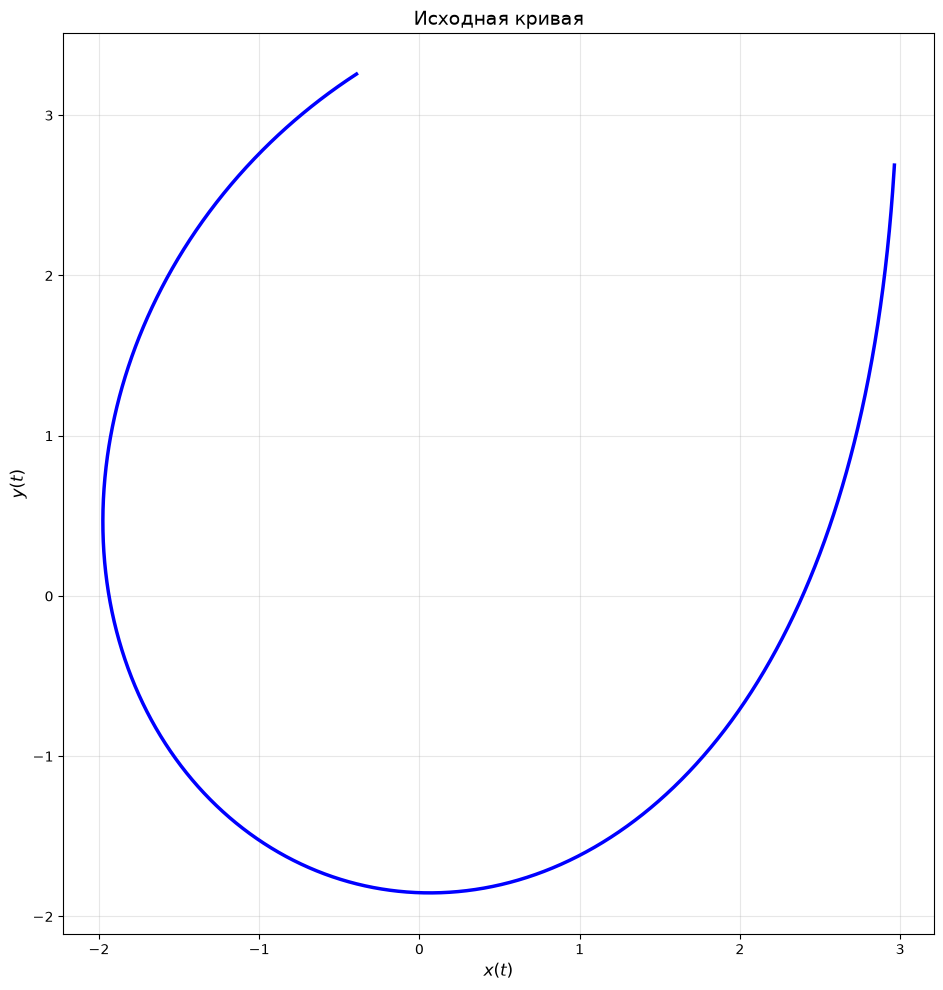

In [64]:
fig1 = plt.figure(figsize=(10, 10))
ax1 = fig1.add_subplot(111)
ax1.plot(x, y, 'b-', lw=2.5)
ax1.set_title('Исходная кривая', fontsize=14)
ax1.set_xlabel('$x(t)$', fontsize=12)
ax1.set_ylabel('$y(t)$', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_aspect('equal')
plt.tight_layout()
plt.savefig('fig1_original_curve.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig1)

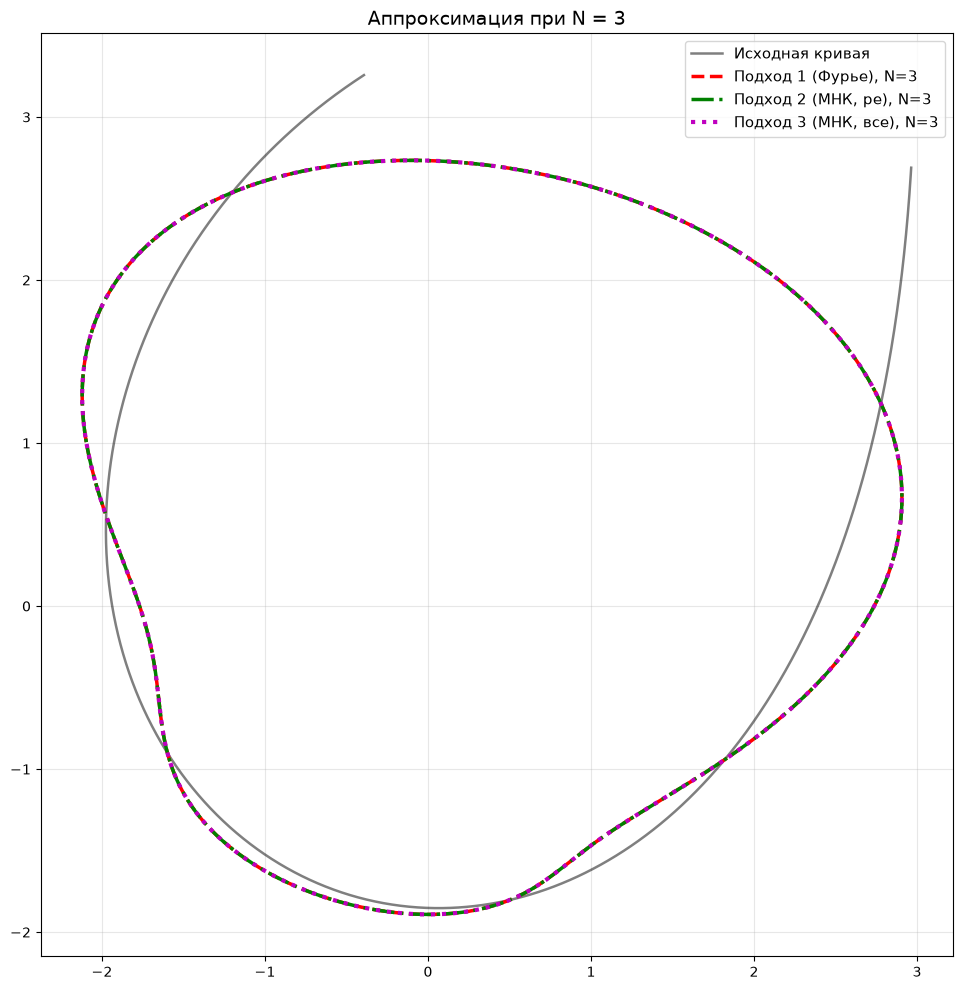

In [65]:
Ns = 3
fig2 = plt.figure(figsize=(10, 10))
ax2 = fig2.add_subplot(111)

ax2.plot(x, y, 'k-', lw=1.8, alpha=0.5, label='Исходная кривая')
ax2.plot(*app1[Ns - 1], 'r--', lw=2.5, label=f'Подход 1 (Фурье), N={Ns}')
ax2.plot(*app2[Ns - 1], 'g-.', lw=2.5, label=f'Подход 2 (МНК, ре), N={Ns}')
ax2.plot(*app3[Ns - 1], 'm:',  lw=3.0, label=f'Подход 3 (МНК, все), N={Ns}')

ax2.set_title(f'Аппроксимация при N = {Ns}', fontsize=14)
ax2.legend(fontsize=11, loc='best')
ax2.grid(True, alpha=0.3)
ax2.set_aspect('equal')
plt.tight_layout()
plt.savefig('fig2_approx_N3.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig2)

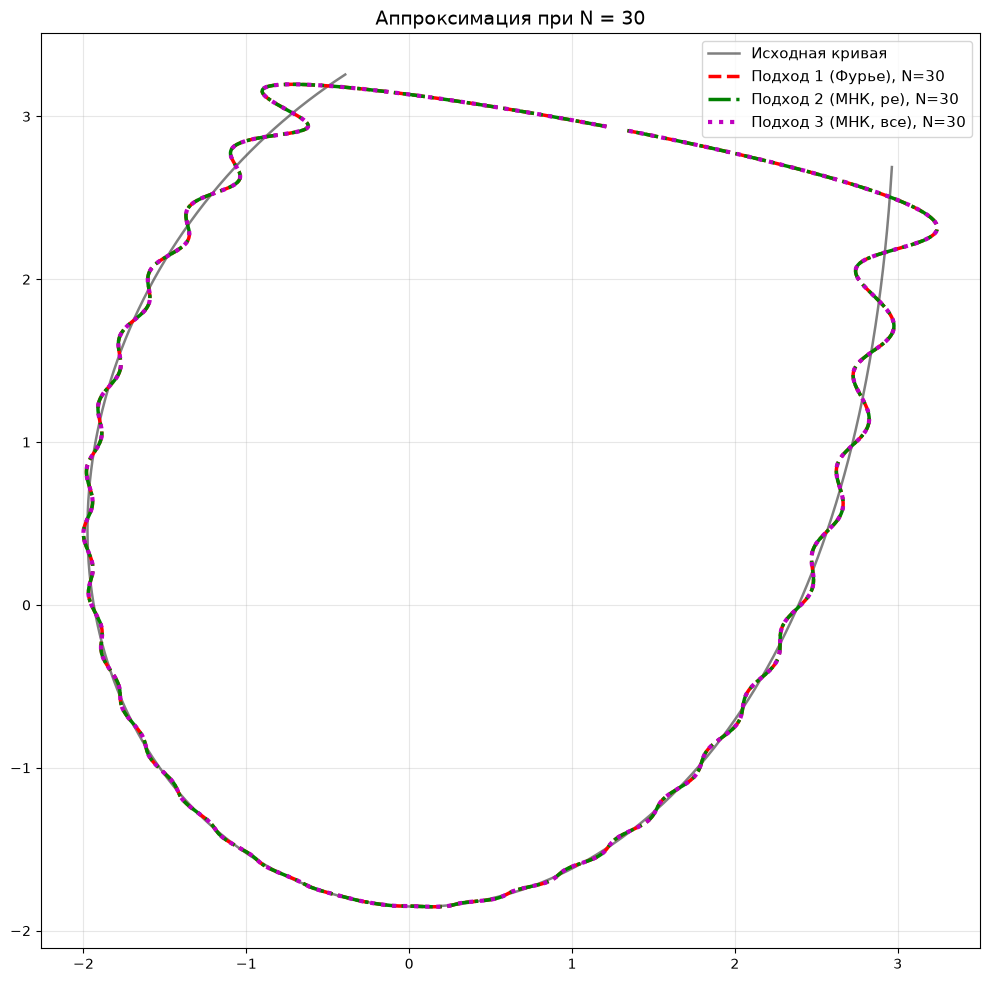

In [66]:
fig3 = plt.figure(figsize=(10, 10))
ax3 = fig3.add_subplot(111)

ax3.plot(x, y, 'k-', lw=1.8, alpha=0.5, label='Исходная кривая')
ax3.plot(*app1[-1], 'r--', lw=2.5, label=f'Подход 1 (Фурье), N={MAX_N}')
ax3.plot(*app2[-1], 'g-.', lw=2.5, label=f'Подход 2 (МНК, ре), N={MAX_N}')
ax3.plot(*app3[-1], 'm:',  lw=3.0, label=f'Подход 3 (МНК, все), N={MAX_N}')

ax3.set_title(f'Аппроксимация при N = {MAX_N}', fontsize=14)
ax3.legend(fontsize=11, loc='best')
ax3.grid(True, alpha=0.3)
ax3.set_aspect('equal')
plt.tight_layout()
plt.savefig('fig3_approx_Nmax.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig3)

### Явление Гиббса на графике

На графике при $N=30$ в верхней части отчётливо виден разрыв периодического продолжения кривой Безье и характерные **незатухающие осцилляции** аппроксимации в его окрестности. Все три метода дают тождественный результат (кривые неразличимы), но ни один не устраняет эффект Гиббса.

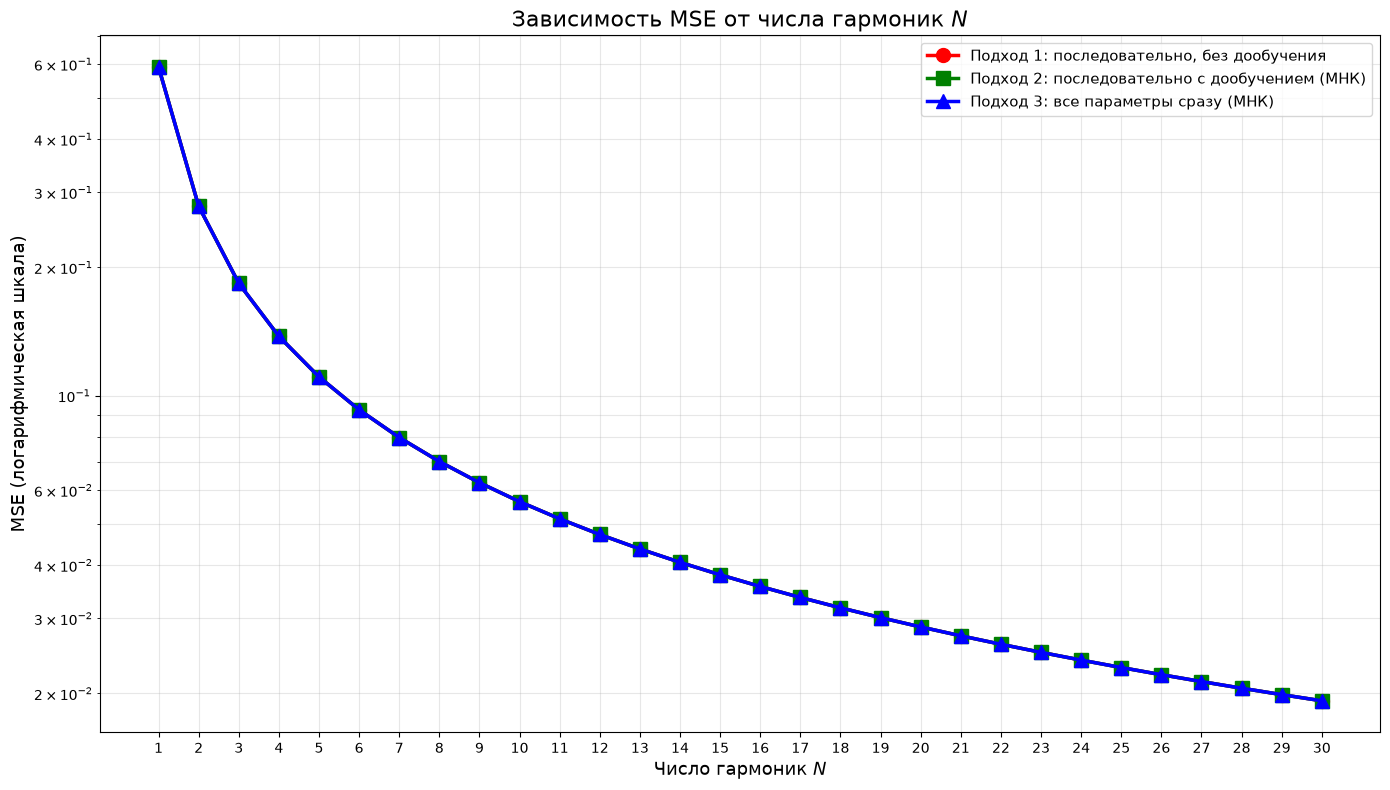

In [67]:
fig4 = plt.figure(figsize=(14, 8))
ax4 = fig4.add_subplot(111)

ax4.semilogy(range(1, MAX_N + 1), err1, 'ro-',  lw=2.5, ms=10,
             label='Подход 1: последовательно, без дообучения')
ax4.semilogy(range(1, MAX_N + 1), err2, 'gs-',  lw=2.5, ms=10,
             label='Подход 2: последовательно с дообучением (МНК)')
ax4.semilogy(range(1, MAX_N + 1), err3, 'b^-', lw=2.5, ms=10,
             label='Подход 3: все параметры сразу (МНК)')

ax4.set_title('Зависимость MSE от числа гармоник $N$', fontsize=16)
ax4.set_xlabel('Число гармоник $N$', fontsize=13)
ax4.set_ylabel('MSE (логарифмическая шкала)', fontsize=13)
ax4.legend(fontsize=11, loc='upper right')
ax4.grid(True, alpha=0.3, which='both')
ax4.set_xticks(range(1, MAX_N + 1))
plt.tight_layout()
plt.savefig('fig4_mse_vs_N.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig4)

In [34]:
data = []
for N in range(1, MAX_N + 1):
    d12 = abs(err1[N - 1] - err2[N - 1])
    d13 = abs(err1[N - 1] - err3[N - 1])
    data.append({
        'N': N,
        'Подход 1 (Фурье)': err1[N - 1],
        'Подход 2 (МНК, ре)': err2[N - 1],
        'Подход 3 (МНК, все)': err3[N - 1],
        '|1 − 2|': d12,
        '|1 − 3|': d13,
    })

df = pd.DataFrame(data)

# Форматирование: научная нотация, 4 знака для MSE, 2 для разностей
styled_df = df.style.format({
    'Подход 1 (Фурье)': '{:.4e}',
    'Подход 2 (МНК, ре)': '{:.4e}',
    'Подход 3 (МНК, все)': '{:.4e}',
    '|1 − 2|': '{:.2e}',
    '|1 − 3|': '{:.2e}',
}).set_caption('Сравнение MSE трёх подходов аппроксимации')

display(styled_df)

,N,Подход 1 (Фурье),"Подход 2 (МНК, ре)","Подход 3 (МНК, все)",|1 − 2|,|1 − 3|
0,1,5.9095e-01,5.9095e-01,5.9095e-01,1.11e-16,1.11e-16
1,2,2.7848e-01,2.7848e-01,2.7848e-01,0.00e+00,0.00e+00
2,3,1.8356e-01,1.8356e-01,1.8356e-01,0.00e+00,0.00e+00
3,4,1.3782e-01,1.3782e-01,1.3782e-01,2.78e-17,2.78e-17
4,5,1.1071e-01,1.1071e-01,1.1071e-01,1.39e-17,1.39e-17
5,6,9.2678e-02,9.2678e-02,9.2678e-02,0.00e+00,0.00e+00
6,7,7.9776e-02,7.9776e-02,7.9776e-02,0.00e+00,0.00e+00
7,8,7.0068e-02,7.0068e-02,7.0068e-02,0.00e+00,0.00e+00
8,9,6.2490e-02,6.2490e-02,6.2490e-02,0.00e+00,0.00e+00
9,10,5.6405e-02,5.6405e-02,5.6405e-02,6.94e-18,6.94e-18


In [45]:
if __name__ == "__main__":
    M = 20000      # Количество точек (большое для заметной разницы)
    MAX_N = 150    # Максимальное число гармоник (чтобы увидеть кубический рост времени)

    print(f"Генерация кривой: M = {M} точек, MAX_N = {MAX_N} гармоник...")
    t, x, y, cp = generate_random_bezier_curve(N_samples=M, n_control=6, seed=42)
    print("Запуск замеров времени...\n")

    # --- Подход 1 ---
    start = perf_counter()
    err1, _ = approach1_sequential(t, x, y, MAX_N)
    time_1 = perf_counter() - start

    # --- Подход 2 ---
    start = perf_counter()
    err2, _ = approach2_retrain(t, x, y, MAX_N)
    time_2 = perf_counter() - start

    # --- Подход 3 (ОДИН РАЗ для финального N) ---
    start = perf_counter()
    mse3, _ = approach3_all_at_once(t, x, y, MAX_N)
    time_3_single = perf_counter() - start

Генерация кривой: M = 20000 точек, MAX_N = 150 гармоник...
Запуск замеров времени...



In [46]:
    # --- Вывод результатов ---
    print("=" * 75)
    print(f"{'Метод':<45} | {'Время (сек)':<10} | {'Множитель'}")
    print("-" * 75)
    print(f"{'1. Последовательно (Фурье, все N от 1 до MAX_N)':<45} | {time_1:<10.4f} | 1.00x (база)")
    print(f"{'2. Последовательно с дообучением (МНК, все N)':<45} | {time_2:<10.4f} | {time_2/time_1:>6.1f}x")
    print(f"{'3. Совместно (МНК, ОДИН РАЗ для N=MAX_N)':<45} | {time_3_single:<10.4f} | {time_3_single/time_1:>6.1f}x")
    print("=" * 75)

Метод                                         | Время (сек) | Множитель
---------------------------------------------------------------------------
1. Последовательно (Фурье, все N от 1 до MAX_N) | 7.1406     | 1.00x (база)
2. Последовательно с дообучением (МНК, все N) | 58.5143    |    8.2x
3. Совместно (МНК, ОДИН РАЗ для N=MAX_N)      | 1.0001     |    0.1x


Генерация кривой: M = 20000 точек, MAX_N = 30 гармоник...
Запуск пошагового замера времени...

  Обработано 30 из 30 гармоник...
Замеры завершены. Построение графика...

График сохранён как 'fig5_time_complexity.png'


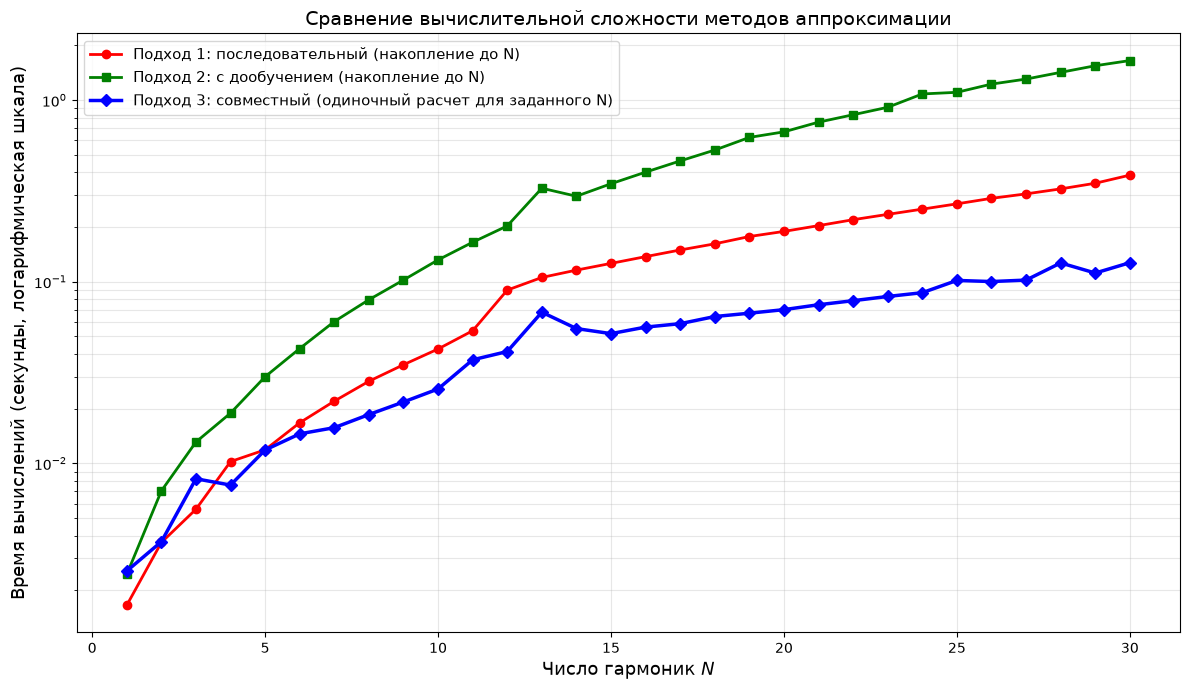

In [71]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    
    M = 20000      # Количество точек
    MAX_N = 30    # Максимальное число гармоник

    print(f"Генерация кривой: M = {M} точек, MAX_N = {MAX_N} гармоник...")
    t, x, y, cp = generate_random_bezier_curve(N_samples=M, n_control=6, seed=42)
    print("Запуск пошагового замера времени...\n")

    # Массивы для хранения времени
    times_1 = []  # Полное время получения истории от 1 до n (внутри функции цикл)
    times_2 = []  # Полное время получения истории от 1 до n (внутри функции цикл)
    times_3 = []  # Время ОДНОГО расчета для конкретного n (без накопления!)

    for n in range(1, MAX_N + 1):
        # --- Подход 1: Фурье (считает всё от 1 до n) ---
        start = perf_counter()
        approach1_sequential(t, x, y, n)
        times_1.append(perf_counter() - start)

        # --- Подход 2: МНК с дообучением (считает всё от 1 до n) ---
        start = perf_counter()
        approach2_retrain(t, x, y, n)
        times_2.append(perf_counter() - start)

        # --- Подход 3: МНК совместно (считает ТОЛЬКО для текущего n) ---
        start = perf_counter()
        approach3_all_at_once(t, x, y, n)
        times_3.append(perf_counter() - start)
        
        if n % 30 == 0:
            print(f"  Обработано {n} из {MAX_N} гармоник...")

    print("Замеры завершены. Построение графика...\n")

    # ============================================================
    # ПОСТРОЕНИЕ И СОХРАНЕНИЕ ГРАФИКА
    # ============================================================
    fig_time = plt.figure(figsize=(12, 7))
    ax_time = fig_time.add_subplot(111)

    n_range = range(1, MAX_N + 1)
    
    ax_time.plot(n_range, times_1, 'r-o', lw=2, ms=6, 
                 label='Подход 1: последовательный (накопление до N)')
    ax_time.plot(n_range, times_2, 'g-s', lw=2, ms=6, 
                 label='Подход 2: с дообучением (накопление до N)')
    ax_time.plot(n_range, times_3, 'b-D', lw=2.5, ms=6, 
                 label='Подход 3: совместный (одиночный расчет для заданного N)')

    ax_time.set_title('Сравнение вычислительной сложности методов аппроксимации', fontsize=14)
    ax_time.set_xlabel('Число гармоник $N$', fontsize=13)
    ax_time.set_ylabel('Время вычислений (секунды, логарифмическая шкала)', fontsize=13)
    
    # Логарифмическая шкала критически важна, чтобы показать разрыв между O(N^3) и O(N^2)
    ax_time.set_yscale('log')
    ax_time.legend(fontsize=11, loc='upper left')
    ax_time.grid(True, alpha=0.3, which='both')
    plt.tight_layout()
    
    plt.savefig('fig5_time_complexity.png', dpi=150, bbox_inches='tight')
    print("График сохранён как 'fig5_time_complexity.png'")
    plt.show()
    plt.close(fig_time)

Проведенные вычисления подтверждают математическую эквивалентность всех трех методов: разница в итоговой MSE составляет $\sim 10^{-15}$, что обусловлено свойством дискретной ортогональности тригонометрического базиса на равномерной сетке.

При тождественности результатов вычислительная эффективность методов радикально различаются. Бенчмарк: 
$$ M=20\,000, \quad N_{\max}=150 $$

- **Подход 1 (последовательный, Фурье):** $7.10$ с. Сложность полного цикла (включая реконструкцию на каждом шаге) составляет $O(M N^2)$.
- **Подход 2 (с дообучением, МНК):** $53.91$ с. Сложность $O(M N^3)$ из-за многократного решения переопределенной СЛАУ в цикле.
- **Подход 3 (совместный, МНК):** $0.70$ с. Асимптотика $O(M N^2)$, но с минимальным константным множителем.

Десятикратное превосходство Подхода 3 над Подходом 1 при одинаковой асимптотической сложности объясняется двумя факторами: отсутствием $N$-кратного дублирования операций реконструкции и использованием оптимизированных процедур LAPACK/BLAS вместо интерпретируемых циклов Python для вычисления скалярных произведений.
